# J3 Manuscript — Reproducibility Notebook

**Spatio-temporal Characterisation of Diurnal Renewable Generation Patterns using Functional Principal Component Analysis**

Run all cells top-to-bottom after setting `DATA_DIR` and `RSA_SHP_PATH` in the Setup cell below.

**Prerequisites**
- Install dependencies: `pip install -r requirements.txt`
- `DATA_DIR`: folder containing the WASA `.npz` files and `WC_3x3.csv`.
- `RSA_SHP_PATH`: path to the Western Cape boundary shapefile (`.shp`).


## 0. Setup

In [ ]:
from pathlib import Path

# ── USER CONFIG ──────────────────────────────────────────────────────────
DATA_DIR     = Path("SETME")   # folder with .npz files and WC_3x3.csv
RSA_SHP_PATH = "SETME"         # path to WC.shp  (Western Cape boundary)
# ─────────────────────────────────────────────────────────────────────────


import sys, os
sys.path.insert(0, str(Path('.').resolve()))  # ensure final/ is importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.colors as colors


from config import (
    YEARS, H, D, Q, K,
    KMEANS_N_INIT, KMEANS_SEED,
    RUN_STABILITY_STUDY, STABILITY_N_RUNS, STABILITY_N_INIT_VALUES,
    HDS_MONTHS, LDS_MONTHS, HDS_TOU, LDS_TOU,
    MORNING_HOURS, MIDDAY_HOURS,
    SUMMER_MONTHS, WINTER_MONTHS,
    COLORS, MARKERS, OUTPUT_DIR,
    apply_rcparams,
)
from data import (
    load_wind, load_coords, align_locations,
    to_daily_matrix, daily_dates,
    compute_tou_means, compute_mean_power_map,
)
from fpca import (
    fit_uncentred_svd, invert_component, r2_about_mean,
    build_scores_dict, mean_pc_scores, centre_scores,
    per_year_decomposition, reconstruct,
    evening_peak_regressions, midday_regressions, cf_pc1_correlation,
)
from fpca_plots import (
    plot_scree, plot_pc_loadings, plot_pc_perturbations,
    plot_components_by_year, plot_residual_std_map,
    plot_mean_score_maps, plot_seasonal_score_maps,
    plot_fig11a, plot_fig11b, plot_fig12, plot_fig13,
    plot_mean_cf_map,
)
from clustering import (
    build_cf_features, build_fpca_features,
    perform_clustering, get_mean_gen_per_cluster,
    sort_clusters, get_distances_between_daily_profiles,
    run_or_load_stability,
)
from clustering_plots import (
    plot_elbow_silhouette_with_piecewise,
    plot_daily_profiles_grid,
    plot_silhouettes_daily,
    plot_cluster_feature_boxplots,
)

apply_rcparams()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Setup complete.")


Setup complete.


## 1. Data loading

In [6]:
wind_df = load_wind(DATA_DIR, years=YEARS)
id_df   = load_coords(DATA_DIR)
wind_df = align_locations(wind_df, id_df)

dates  = daily_dates(wind_df)
n_locs = len(wind_df.columns)
n_days = len(dates)
print(f"{n_locs} locations, {n_days} days, {len(wind_df)} hours")

X = to_daily_matrix(wind_df)
print(f"Daily-profile matrix X: {X.shape}")


10850 locations, 1825 days, 43800 hours
Daily-profile matrix X: (19801250, 24)


In [8]:
tou_means = compute_tou_means(
    wind_df,
    hds_months=HDS_MONTHS,
    lds_months=LDS_MONTHS,
    hds_tou=HDS_TOU,
    lds_tou=LDS_TOU,
    morning_hours=MORNING_HOURS,
    midday_hours=MIDDAY_HOURS,
)
print("TOU feature table shape:", tou_means.shape)
tou_means.head(3)


TOU feature table shape: (10850, 38)


,hds_off_peak,hds_off_peak_std,hds_standard,hds_standard_std,hds_m_peak,hds_m_peak_std,hds_e_peak,hds_e_peak_std,hds_peak,hds_peak_std,...,overall_peak,overall_peak_std,hds_midday,hds_midday_std,lds_midday,lds_midday_std,midday,midday_std,morning_mean,capacity_factor
22222,0.479899,0.346834,0.482600,0.353098,0.475894,0.350999,0.498736,0.347752,0.485031,0.349807,...,0.484053,0.334216,0.475837,0.357736,0.530789,0.305819,0.516938,0.320569,0.462525,0.485992
22223,0.481855,0.347862,0.484096,0.352594,0.477944,0.350816,0.500248,0.347152,0.486865,0.349450,...,0.482700,0.334297,0.478045,0.356761,0.530357,0.306883,0.517171,0.320973,0.461443,0.485567
22851,0.476717,0.346913,0.481265,0.351693,0.465785,0.353252,0.493144,0.347706,0.476729,0.351224,...,0.478955,0.333806,0.476308,0.355606,0.535481,0.300185,0.520566,0.316100,0.454832,0.481875


## 2. Functional PCA

In [9]:
svd_model, scores, components = fit_uncentred_svd(X, n_components=Q + 4)

# Invert component 0 (PC1) so that its loading is positive
scores, components = invert_component(scores, components, k=0)

r2_ind, r2_cum, mean_share = r2_about_mean(X, svd_model)
print(f"Mean-profile share of total SS: {mean_share:.4f}")
print(f"Cumulative R\u00b2 for Q={Q} modes: {r2_cum[Q-1]:.4f}")


Mean-profile share of total SS: 0.5378
Cumulative R² for Q=4 modes: 0.8617


In [10]:
scores_dict = build_scores_dict(
    scores,
    n_locations=n_locs,
    dates=dates,
    location_ids=wind_df.columns,
    n_modes=Q,
)
centered_scores_dict = centre_scores(scores_dict, pc="PC1")


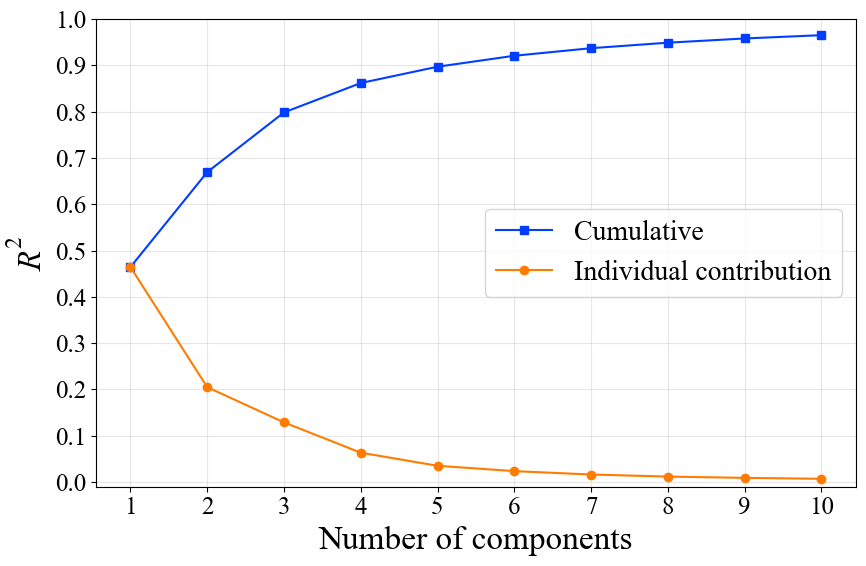

In [11]:
fig, ax = plot_scree(
    r2_ind, r2_cum,
    n_plot=10,
    save_path=OUTPUT_DIR / "fig04_scree.png",
)
plt.show()


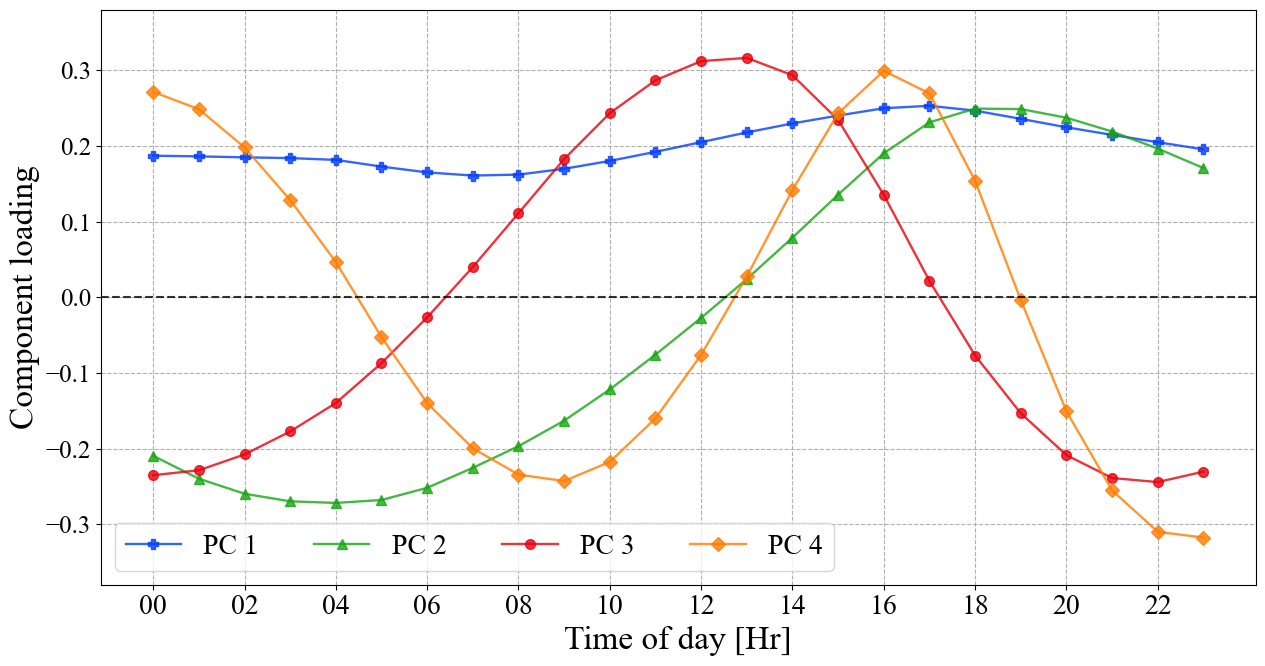

In [12]:
fig, ax = plot_pc_loadings(
    components=components,
    modes=(1, 2, 3, 4),
    colors=COLORS[:4],
    markers=MARKERS[:4],
    save_path=OUTPUT_DIR / "fig05_loadings.png",
)
plt.show()


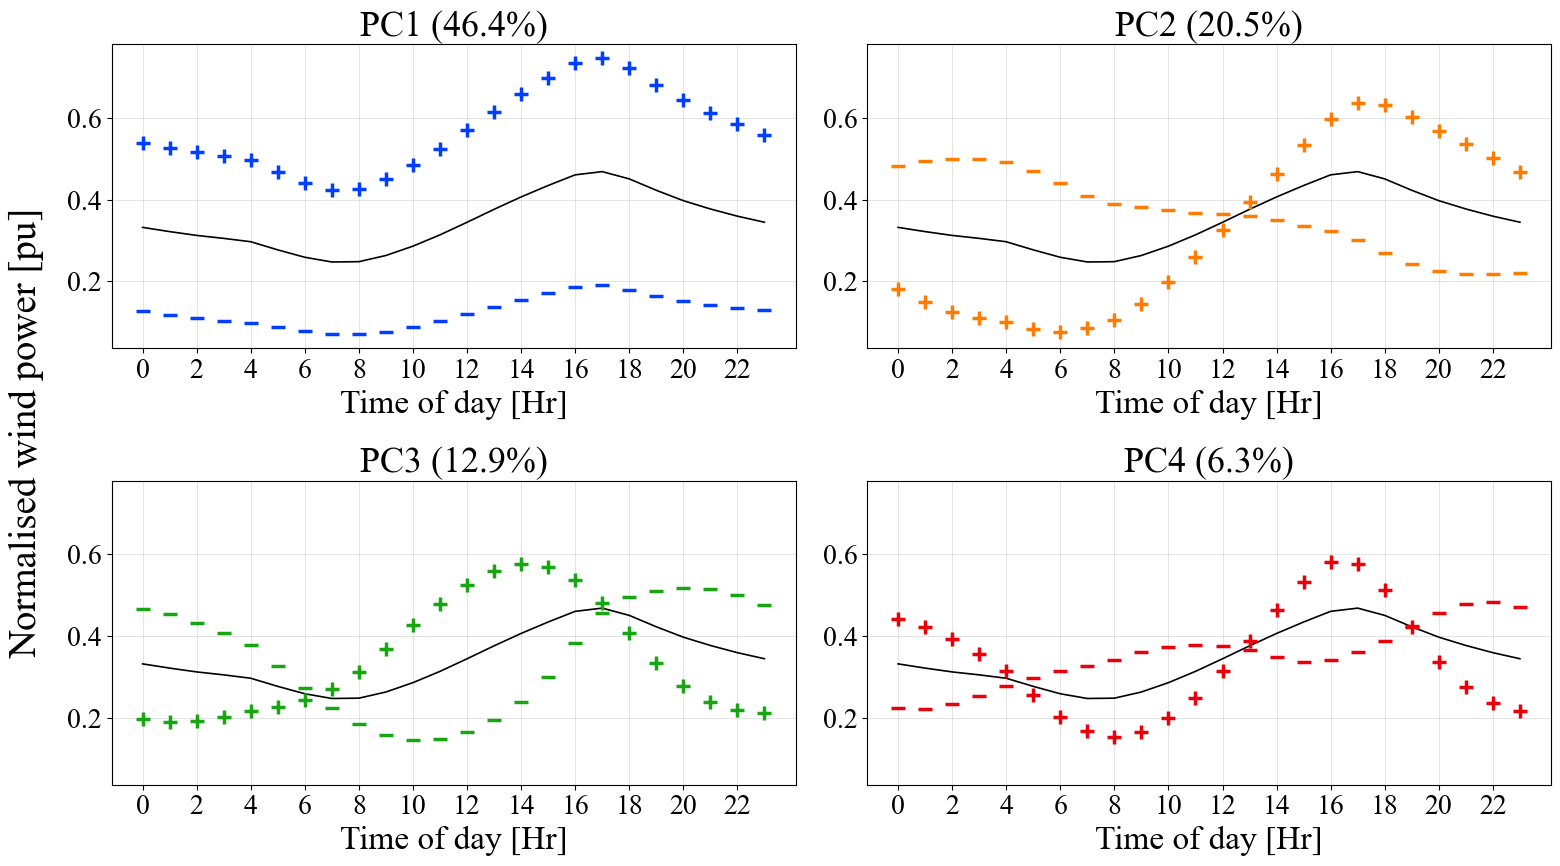

In [13]:
r2_pct = r2_ind[:Q] * 100
fig, axes = plot_pc_perturbations(
    X=X,
    scores=scores,
    components=components,
    explained=r2_pct,
    n_plot=Q,
    c=1.0,
    save_path=OUTPUT_DIR / "fig06_perturbations.png",
)
plt.show()


In [14]:
year_components, year_r2, match_df = per_year_decomposition(
    wind_df=wind_df,
    pooled_components=components,
    n_modes=Q,
    n_return=Q + 4,
)
print(match_df.to_string(index=False))


 year  pooled_PC  year_PC  sign  tucker_congruence  r2_ind
 2014          1        1    -1             0.9999  0.4687
 2014          2        2     1             0.9991  0.2049
 2014          3        3     1             0.9991  0.1264
 2014          4        4     1             0.9996  0.0627
 2015          1        1    -1             0.9998  0.4561
 2015          2        2     1             0.9997  0.2086
 2015          3        3     1             0.9994  0.1318
 2015          4        4    -1             0.9993  0.0641
 2016          1        1    -1             0.9999  0.4586
 2016          2        2     1             0.9999  0.2097
 2016          3        3    -1             0.9999  0.1334
 2016          4        4    -1             0.9999  0.0646
 2017          1        1    -1             0.9999  0.4578
 2017          2        2    -1             0.9992  0.2020
 2017          3        3     1             0.9990  0.1265
 2017          4        4     1             0.9995  0.06

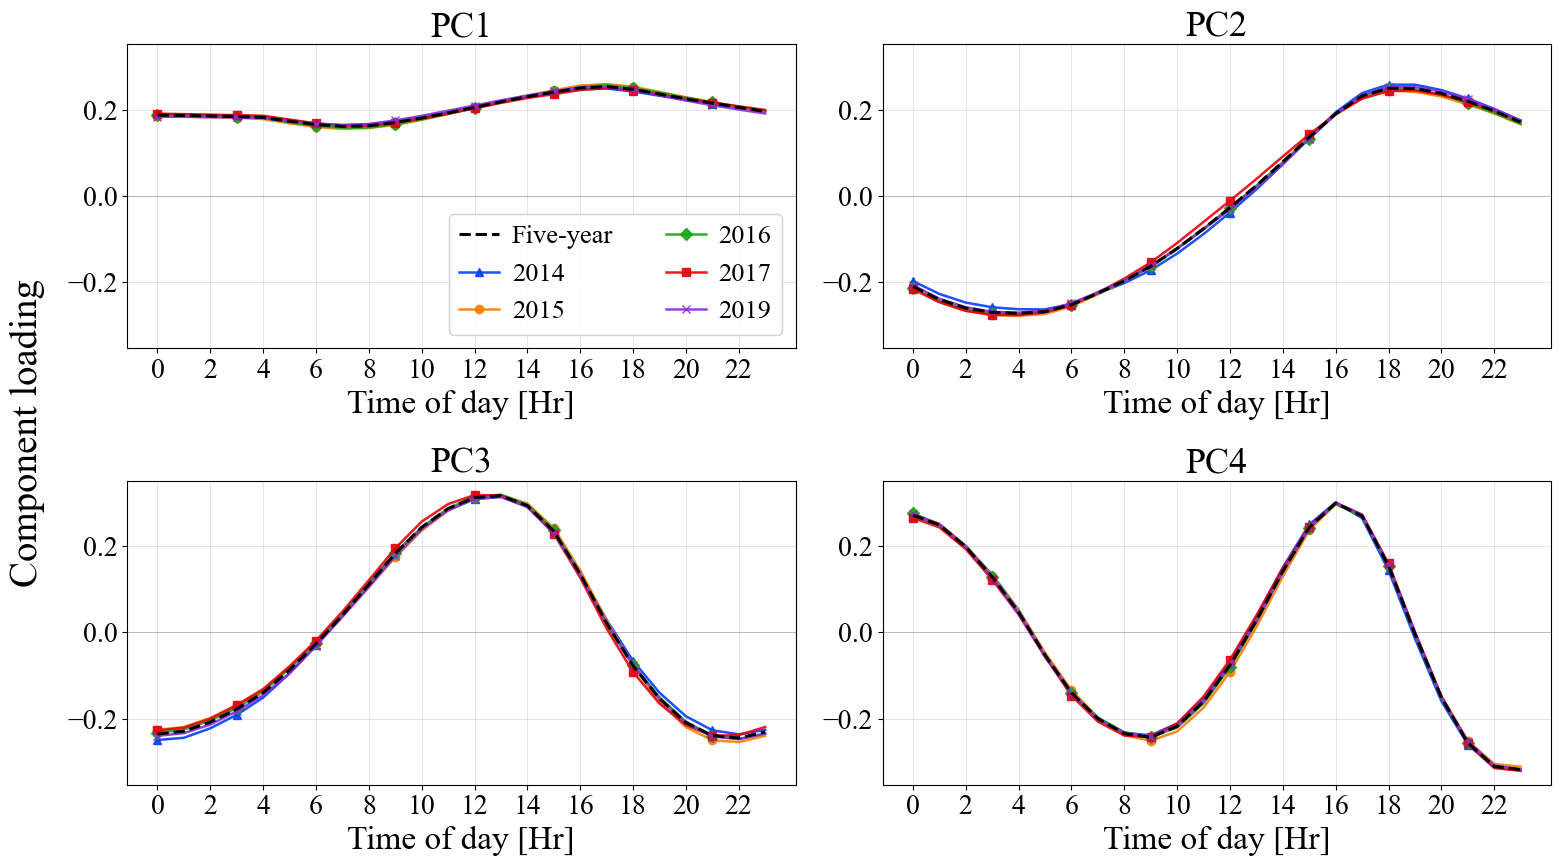

In [15]:
fig, axes = plot_components_by_year(
    pooled=components,
    year_components=year_components,
    year_r2=year_r2,
    pooled_r2=r2_ind,
    n_plot=Q,
    save_path=OUTPUT_DIR / "fig07_year_components.png",
)
plt.show()


## 3. Spatial maps

In [16]:
id_df_means = compute_mean_power_map(wind_df, id_df)


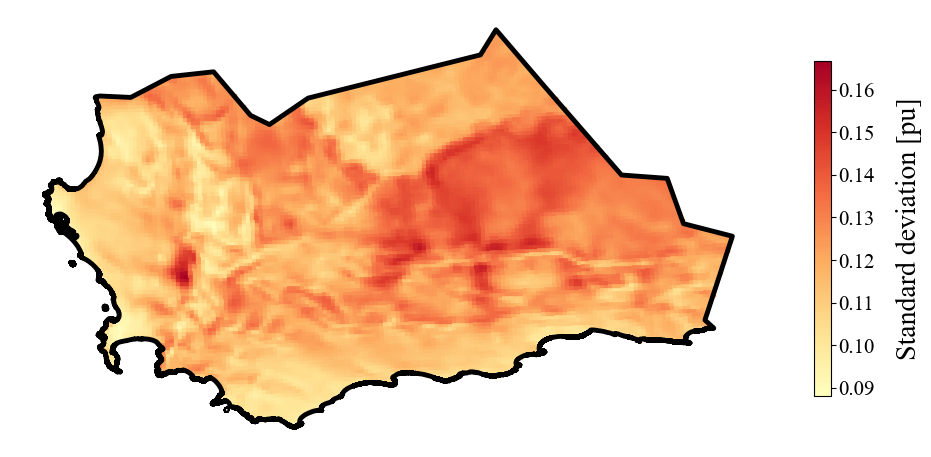

In [45]:
reconstructed_df = reconstruct(
    svd_model, Q=Q,
    original_index=wind_df.index,
    original_columns=wind_df.columns,
)
residuals     = wind_df - reconstructed_df
residuals_std = residuals.std()

def truncate_colormap(cmap_name, minval=0.5, maxval=1.0, n=256):
    """
    Truncates a standard colormap to a specific range.
    minval and maxval should be between 0.0 and 1.0.
    """
    cmap = plt.get_cmap(cmap_name)
    # Sample the original colormap between minval and maxval
    new_cmap = colors.LinearSegmentedColormap.from_list(
        f'trunc_{cmap_name}', cmap(np.linspace(minval, maxval, n))
    )
    return new_cmap

# 1. Create a colormap that only uses the top half (50% to 100%) of viridis
upper_cmap = truncate_colormap("RdYlBu_r", minval=0.5, maxval=1.0)


fig, ax = plot_residual_std_map(
    residuals_std=residuals_std,
    id_df=id_df,
    upper_cmap=upper_cmap,
    rsa_shp_path=RSA_SHP_PATH,
    save_path=OUTPUT_DIR / "fig08_residual_std.png",
)
plt.show()


### Mean score maps PC1–PC4

C:\Users\23726059\Documents\PCA LMU SU\pca_daily\final\..\src\map_plotter.py:527: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


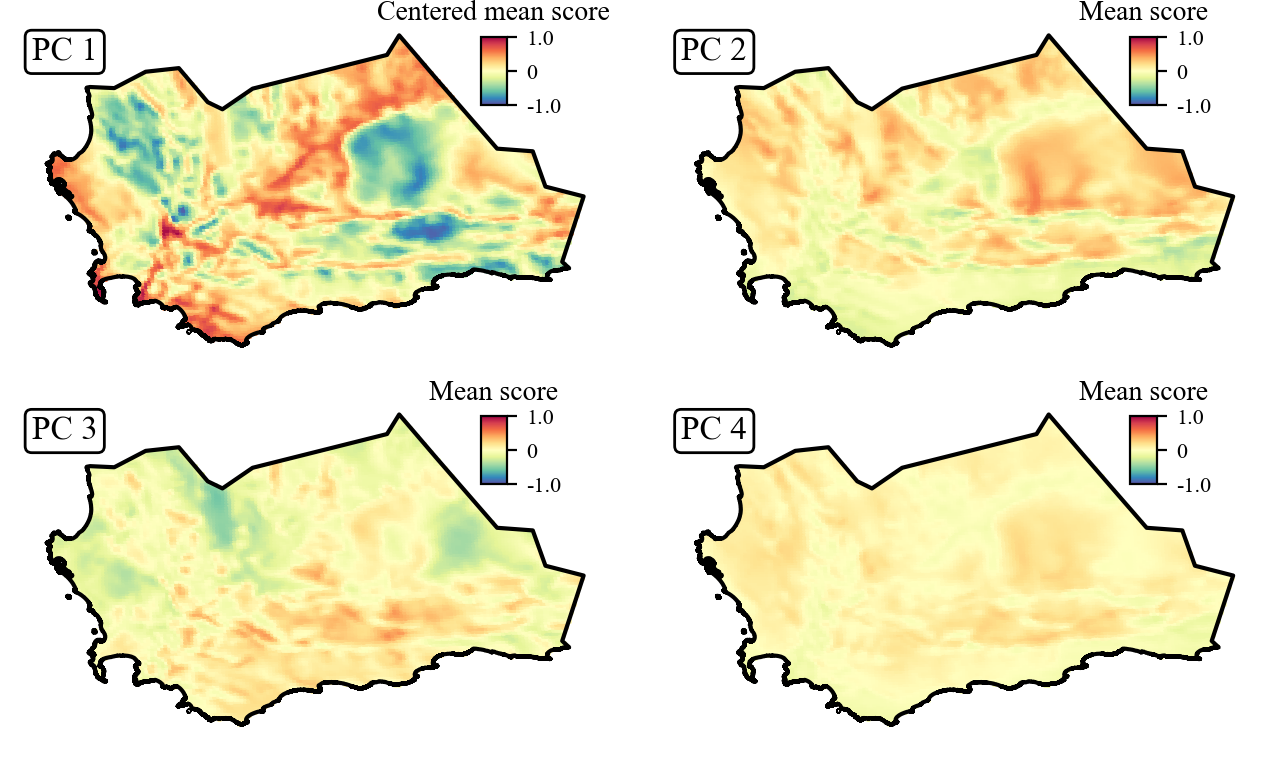

In [19]:
fig, axes = plot_mean_score_maps(
    centered_pc1_scores_dict=centered_scores_dict,
    id_df=id_df,
    rsa_shp_path=RSA_SHP_PATH,
    save_path=OUTPUT_DIR / "fig09_mean_scores.png",
)
plt.show()


### Seasonal score maps

vmin: -1.44, vmax: 1.44
vmin: -1.00, vmax: 1.00
vmin: -1.00, vmax: 1.00
vmin: -1.00, vmax: 1.00


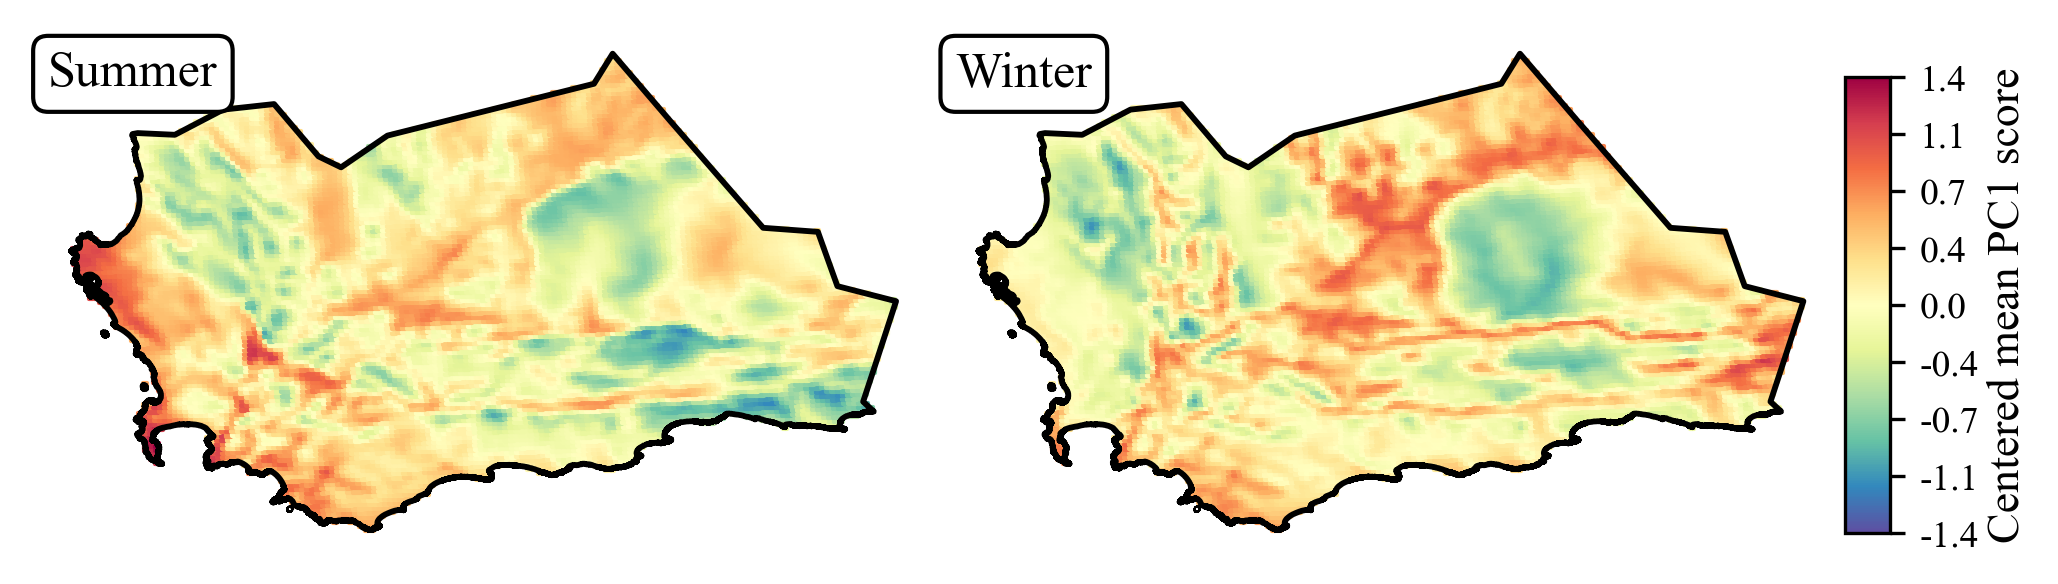

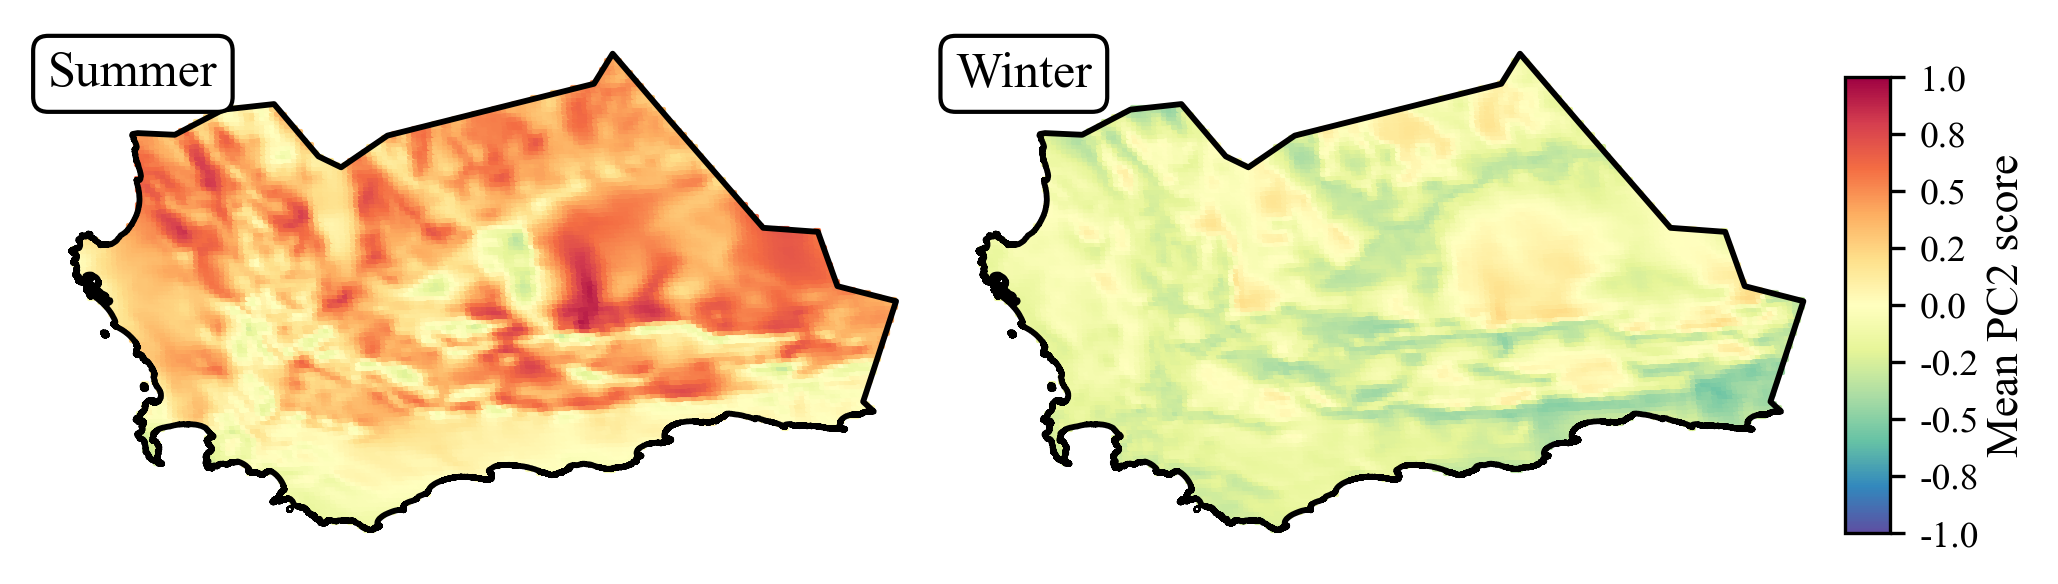

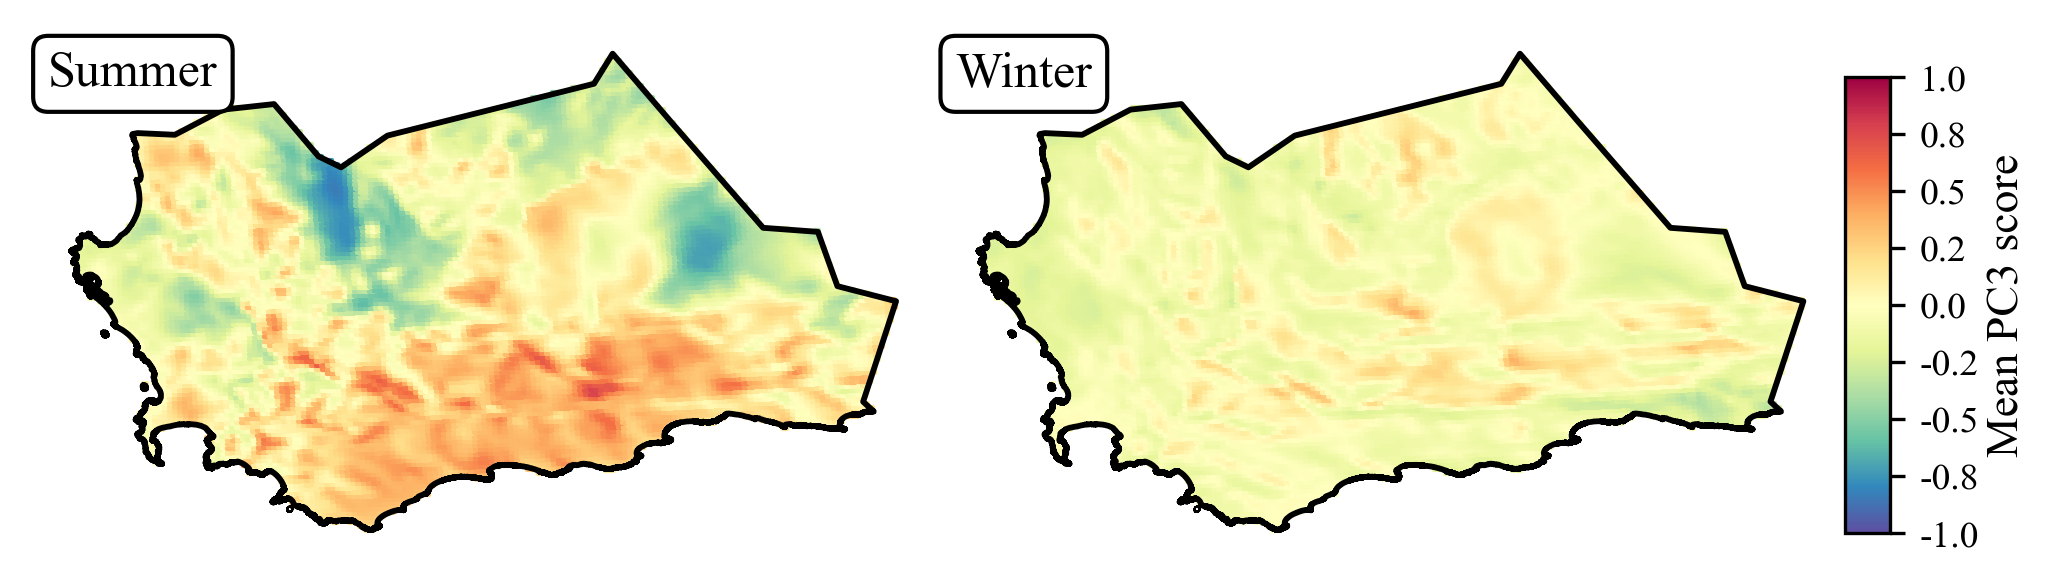

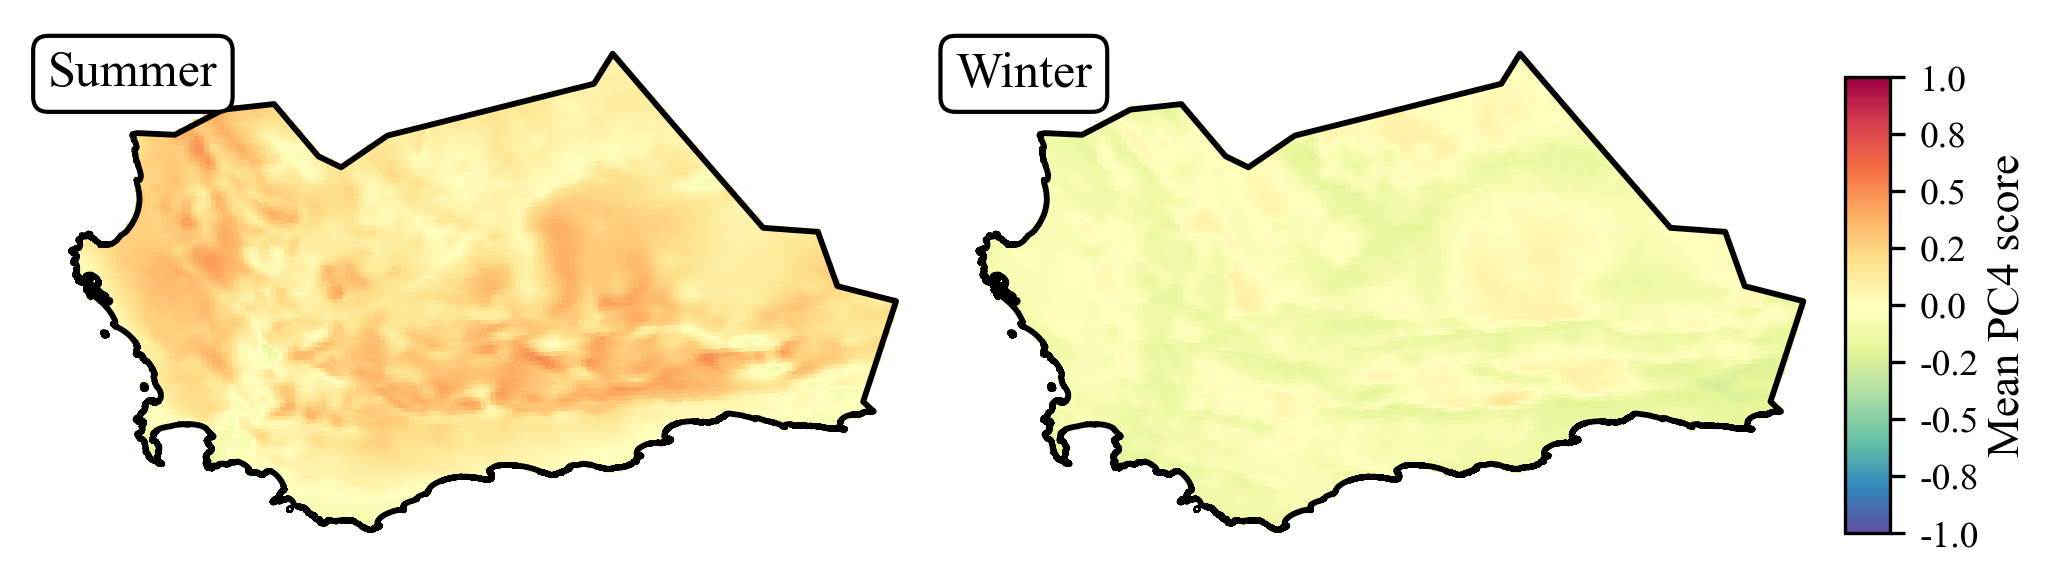

In [20]:
results_seasonal = plot_seasonal_score_maps(
    centered_scores_dict=centered_scores_dict,
    scores_dict=scores_dict,
    id_df=id_df,
    rsa_shp_path=RSA_SHP_PATH,
    years=YEARS,
    save_path_pc1=OUTPUT_DIR / "fig10a_pc1_seasonal.png",
    save_path_template=str(OUTPUT_DIR / "fig10_pc{pc}_seasonal.png"),
)
for fig, ax in results_seasonal:
    plt.show()


## 4. TOU period regressions

In [21]:
mean_pc_df = mean_pc_scores(scores_dict, n_modes=Q)


### Evening peak vs CF (colour = PC1)

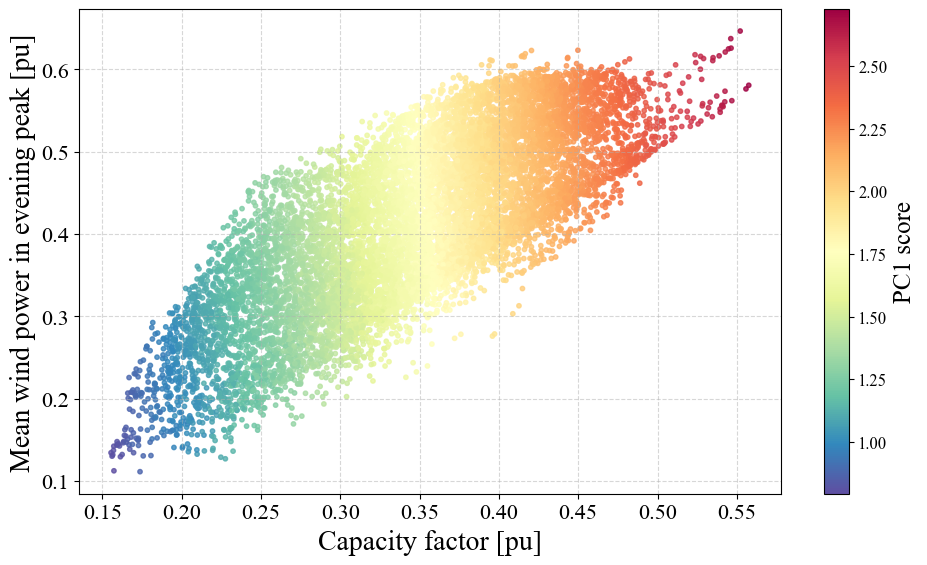

In [22]:
fig, ax = plot_fig11a(tou_means, mean_pc_df, save_path=OUTPUT_DIR / "fig11a.png")
plt.show()


### Evening peak vs CF (colour = PC2)

Evening peak — R²(CF): 0.5836  R²(CF+PC2): 0.9162


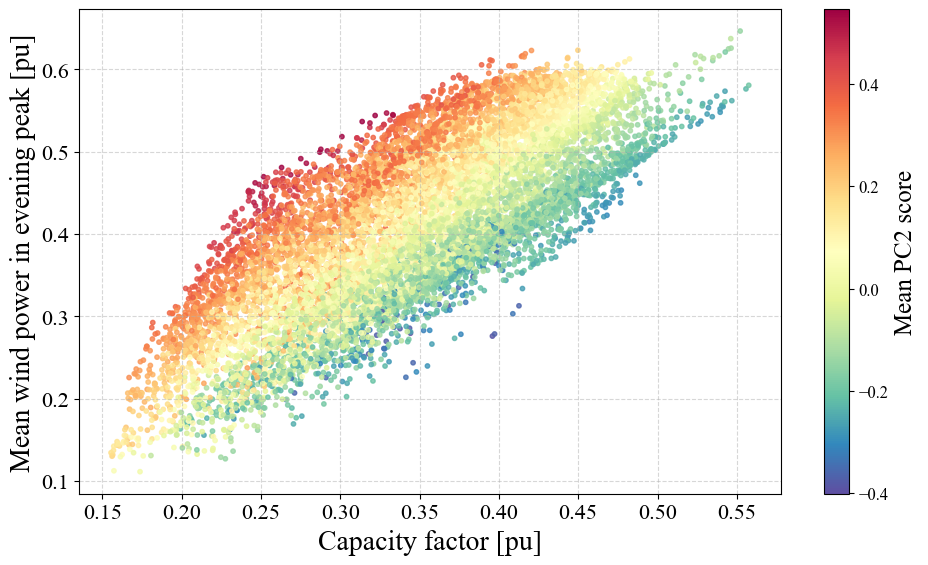

In [23]:
r2_ep = evening_peak_regressions(tou_means, mean_pc_df)
print(f"Evening peak \u2014 R\u00b2(CF): {r2_ep['r2_cf']:.4f}  "
      f"R\u00b2(CF+PC2): {r2_ep['r2_cf_pc2']:.4f}")
fig, ax = plot_fig11b(tou_means, mean_pc_df, save_path=OUTPUT_DIR / "fig11b.png")
plt.show()


### Morning mean vs CF (colour = PC2)

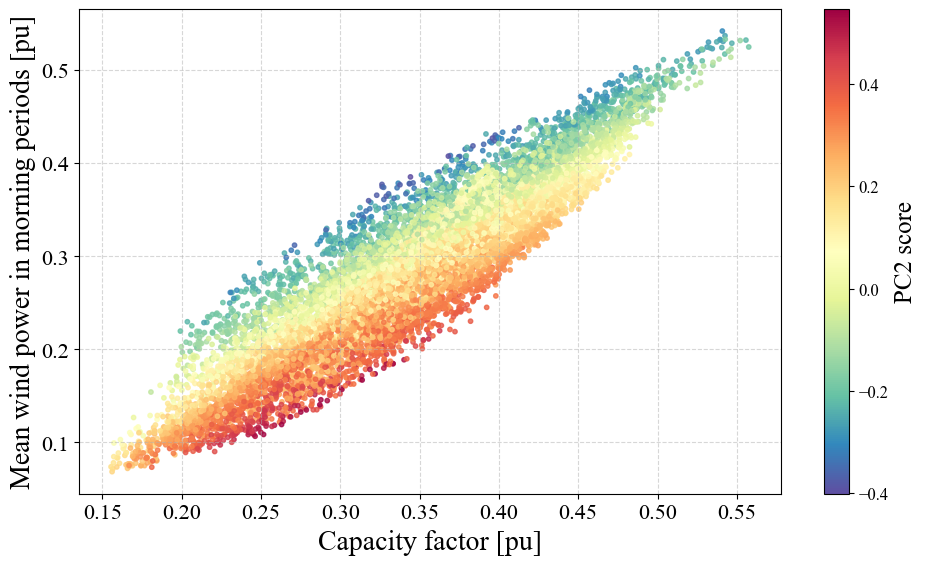

In [24]:
fig, ax = plot_fig12(tou_means, mean_pc_df, save_path=OUTPUT_DIR / "fig12_morning.png")
plt.show()


### Midday mean vs CF (colour = PC3)

Midday — R²(CF): 0.6654  R²(CF+PC3): 0.9793


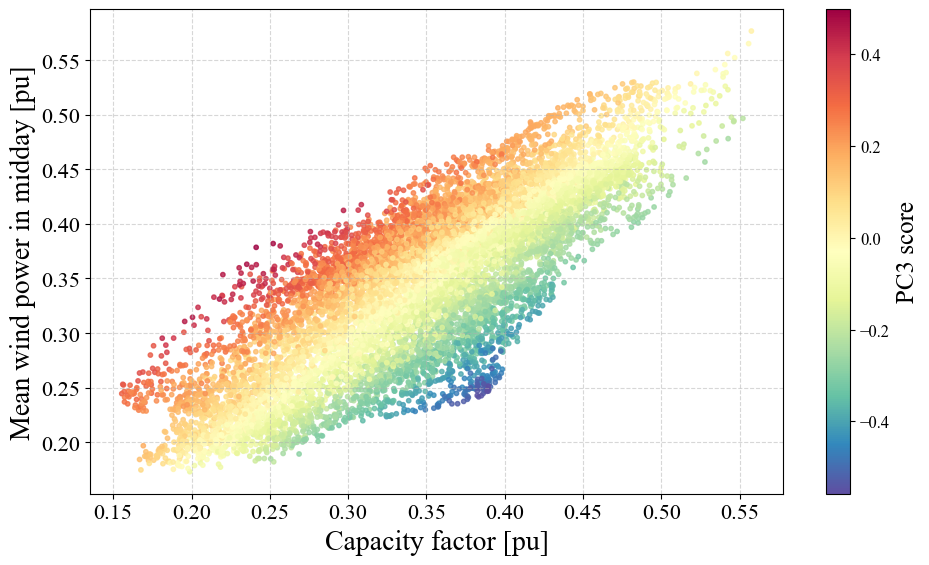

In [25]:
r2_md = midday_regressions(tou_means, mean_pc_df)
print(f"Midday \u2014 R\u00b2(CF): {r2_md['r2_cf']:.4f}  "
      f"R\u00b2(CF+PC3): {r2_md['r2_cf_pc3']:.4f}")
fig, ax = plot_fig13(tou_means, mean_pc_df, save_path=OUTPUT_DIR / "fig13_midday.png")
plt.show()


In [26]:
corr_cf_pc1 = cf_pc1_correlation(tou_means, mean_pc_df)
print(f"CF\u2013PC1 Pearson r: {corr_cf_pc1['pearson_r']:.4f}  "
      f"R\u00b2: {corr_cf_pc1['r2']:.4f}")


CF–PC1 Pearson r: 0.9978  R²: 0.9956


## 5. Clustering

In [27]:
id_df_indexed = id_df.set_index("ID")
cf_features   = build_cf_features(wind_df)
fpca_features = build_fpca_features(mean_pc_df, n_modes=Q)


### Elbow / silhouette (FPCA features)

Elbow point detected at k = 7
Line intersection at k = 6.81
Reduced range: 4 – 9
Optimal k (silhouette within reduced range): 4
Silhouette scores within reduced range: {4: 0.30336316580408934, 5: 0.2810976498958205, 6: 0.28484755212333035, 7: 0.2880628423966633, 8: 0.2749406134084685, 9: 0.2670378292386421}
Highlighted cluster 7 with silhouette score: 0.2881


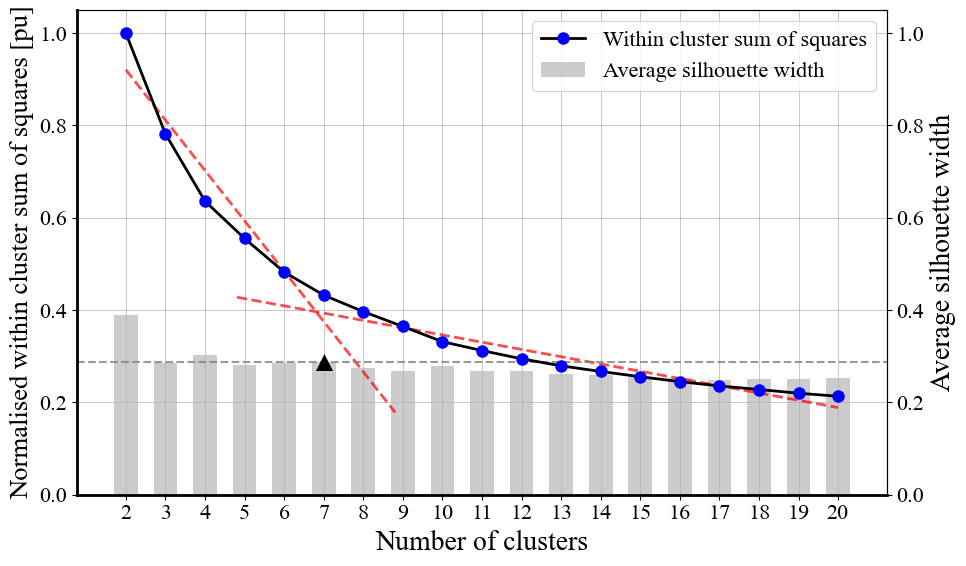

Silhouette scores: [0.38933025592959136, 0.28516526078053306, 0.30336316580408934, 0.2810976498958205, 0.28484755212333035, 0.2880628423966633, 0.2749406134084685, 0.2670378292386421, 0.2781593726506709, 0.26857233511041606, 0.26703995466456987, 0.26141910416997344, 0.2591187637790537, 0.25399698560556294, 0.25187352104290966, 0.24793132347490968, 0.25108815836031056, 0.2515033491078396, 0.2533617094535456]


In [28]:
elbow_fpca = plot_elbow_silhouette_with_piecewise(
    X=fpca_features,
    k_range=range(2, 21),
    show_piecewise=True,
    sil_cluster=K,
    save_path=OUTPUT_DIR / "fig14a_elbow_fpca.png",
)


### Elbow / silhouette (CF feature)

Elbow point detected at k = 5
Line intersection at k = 4.89
Reduced range: 2 – 7
Optimal k (silhouette within reduced range): 2
Silhouette scores within reduced range: {2: 0.5779473389659342, 3: 0.5444615366488018, 4: 0.544400331488524, 5: 0.529648595584403, 6: 0.5240093801359115, 7: 0.5295293633291068}
Highlighted cluster 7 with silhouette score: 0.5295


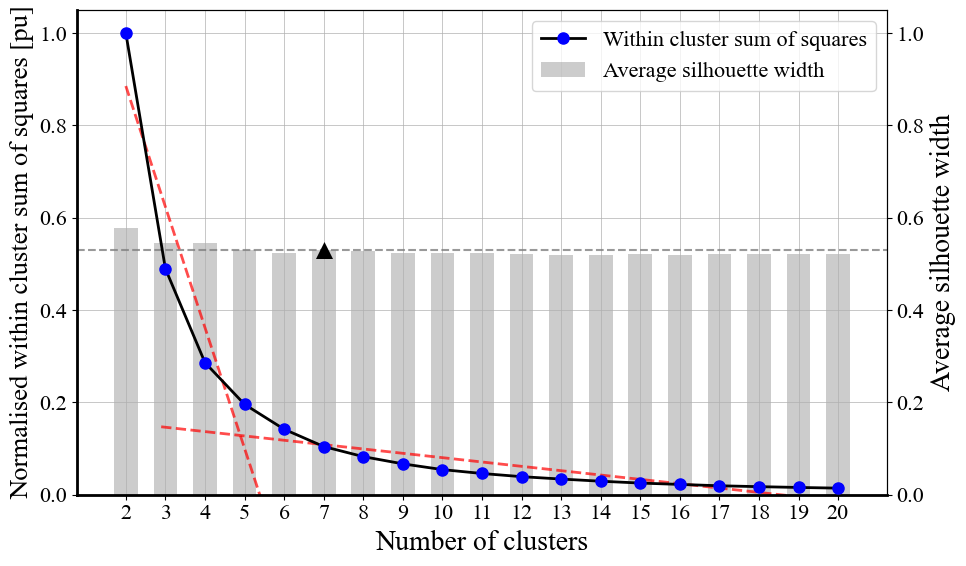

Silhouette scores: [0.5779473389659342, 0.5444615366488018, 0.544400331488524, 0.529648595584403, 0.5240093801359115, 0.5295293633291068, 0.5271337563459656, 0.5240150887257072, 0.5237909860187333, 0.5241754342216207, 0.5209388713569783, 0.520041207207336, 0.5191450109505998, 0.5210641609183555, 0.5197252980513906, 0.5224911842467951, 0.5203804752794856, 0.5210868651545564, 0.5218738581589116]


In [29]:
elbow_cf = plot_elbow_silhouette_with_piecewise(
    X=cf_features,
    k_range=range(2, 21),
    show_piecewise=True,
    sil_cluster=K,
    save_path=OUTPUT_DIR / "fig14b_elbow_cf.png",
)


### FPCA clustering (K=7)

In [30]:
id_df_clusters_pc = perform_clustering(
    data=fpca_features,
    n_clusters=K,
    id_df=id_df_indexed,
    feature_cols=["PC1", "PC2", "PC3", "PC4"],
)
id_df_clusters_pc.reset_index(inplace=True)

pc_mean_gen_stats = get_mean_gen_per_cluster(id_df_clusters_pc, wind_df)

stability_summary_pc, _ = run_or_load_stability(
    data=fpca_features,
    n_clusters=K,
    feature_cols=["PC1", "PC2", "PC3", "PC4"],
    cache_path=OUTPUT_DIR / "stability_fpca",
    run=RUN_STABILITY_STUDY,
    n_runs=STABILITY_N_RUNS,
    n_init_values=STABILITY_N_INIT_VALUES,
)
print(stability_summary_pc.to_string(index=False))

sorted_ids_clusters_pc, sorted_stats_pc = sort_clusters(
    id_df_clusters_pc, pc_mean_gen_stats, sort_by="Mean_Generation"
)
sorted_ids_clusters_pc.to_csv(OUTPUT_DIR / "cluster_assignments_fpca_k7.csv", index=False)
print(sorted_ids_clusters_pc.head(3))


 n_init  ari_mean  ari_min  ari_frac_above_0.99  inertia_mean  inertia_std  n_distinct_solutions
      1  0.783585 0.382210             0.095075    468.592387     5.275679                   157
      5  0.963971 0.869821             0.148894    465.279765     0.124708                   176
     10  0.983582 0.913284             0.271055    465.223315     0.026756                   178
     20  0.989668 0.957201             0.495930    465.210910     0.009850                   160
     50  0.992568 0.977324             0.674372    465.206088     0.002974                   155
      ID   Latitude  Longitude  Cluster  clustered_on PC1  clustered_on PC2  \
0  22222 -34.823544  19.970032        7          2.370646         -0.222084   
1  22223 -34.822390  20.007294        7          2.369254         -0.218853   
2  22851 -34.794080  19.931427        7          2.351418         -0.214920   

   clustered_on PC3  clustered_on PC4  cluster_mean_Generation  
0          0.068279         -0.11151

### Daily profiles by cluster (FPCA features)

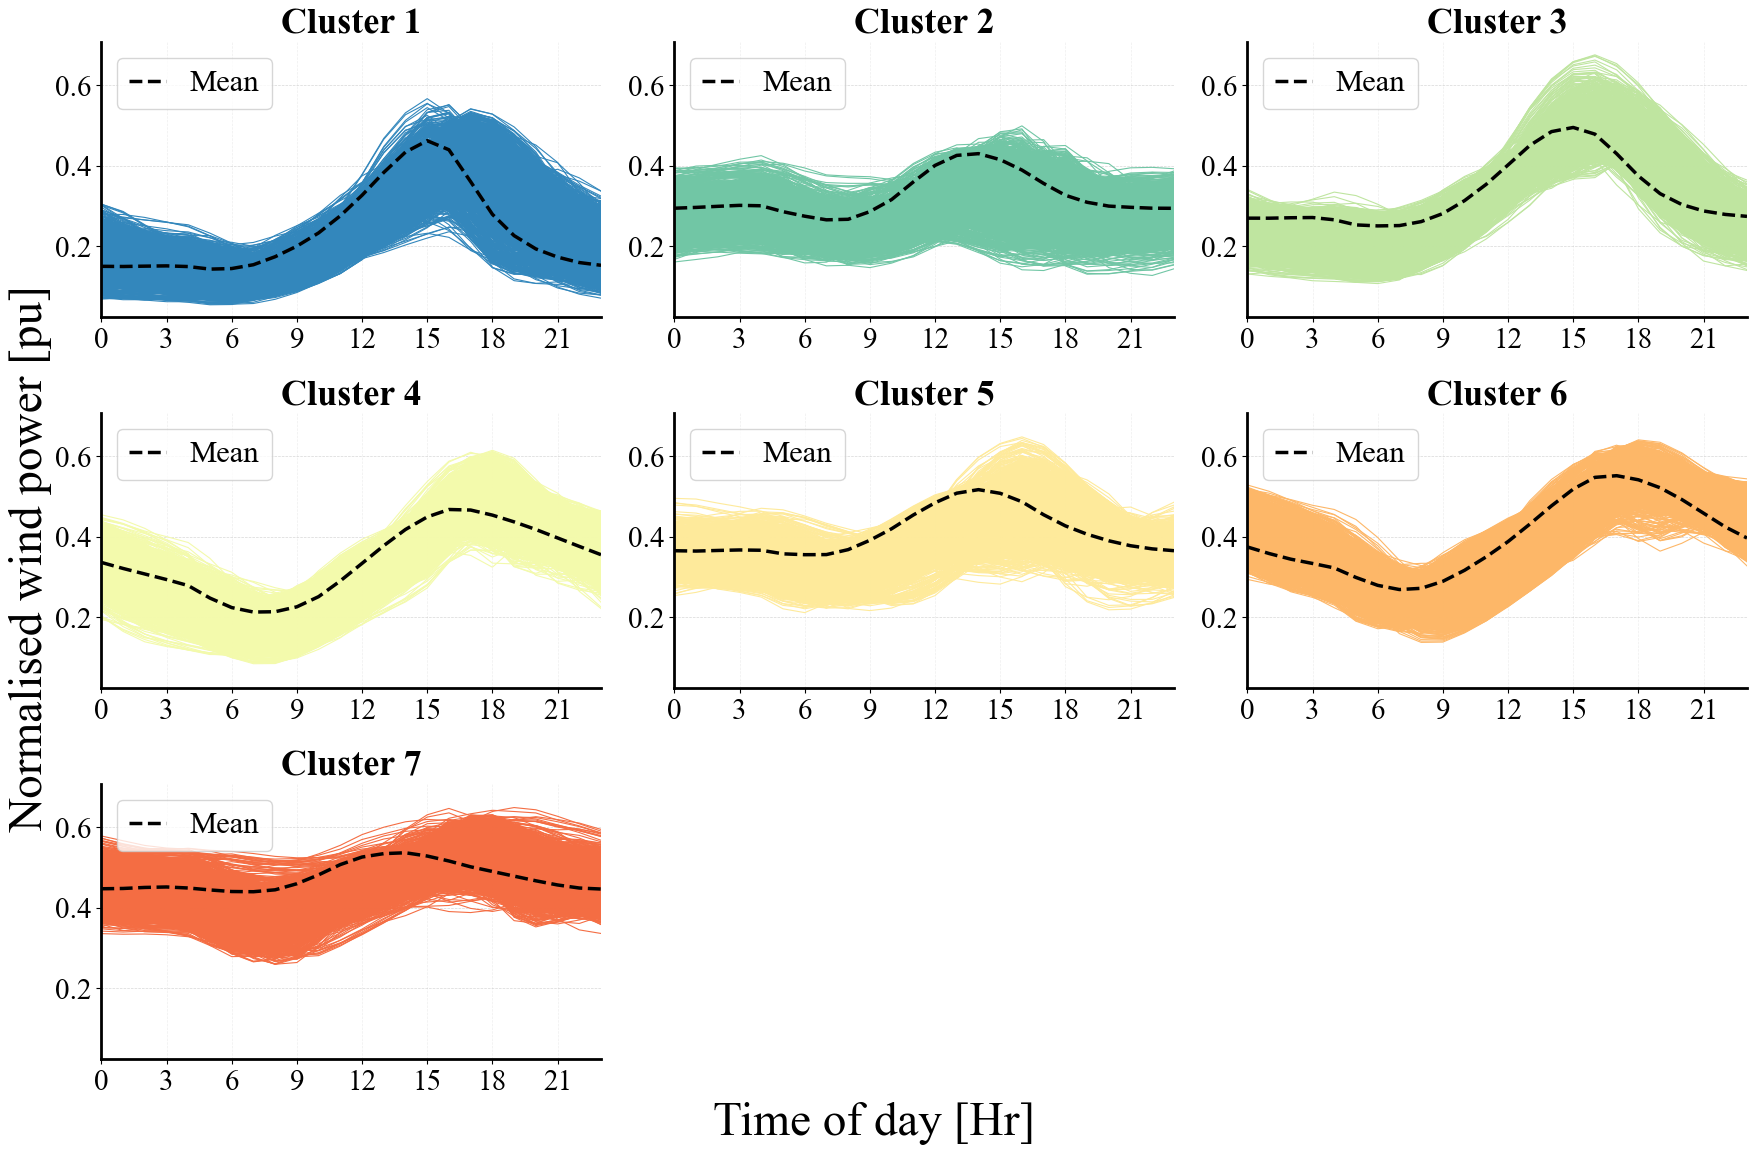

In [31]:
fig, axes = plot_daily_profiles_grid(
    wind_df=wind_df,
    id_df=sorted_ids_clusters_pc,
    save_path=OUTPUT_DIR / "fig15_profiles_fpca.png",
)
plt.show()


### Silhouette (FPCA clustering)

Calculating daily profiles for each location...

Calculating intra-cluster distances...
Cluster 1: 1447 profiles, Avg Euclidean dist: 0.3198, Avg Cosine dist: 0.0289
Cluster 2: 1331 profiles, Avg Euclidean dist: 0.3112, Avg Cosine dist: 0.0160
Cluster 3: 1168 profiles, Avg Euclidean dist: 0.2921, Avg Cosine dist: 0.0119
Cluster 4: 1420 profiles, Avg Euclidean dist: 0.2978, Avg Cosine dist: 0.0122
Cluster 5: 2090 profiles, Avg Euclidean dist: 0.2756, Avg Cosine dist: 0.0087
Cluster 6: 1824 profiles, Avg Euclidean dist: 0.2822, Avg Cosine dist: 0.0086
Cluster 7: 1570 profiles, Avg Euclidean dist: 0.2778, Avg Cosine dist: 0.0058

Calculating silhouette scores...

SUMMARY
Number of locations: 10850
Number of clusters: 7

Global Silhouette Scores:
  - Euclidean: 0.2669
  - Cosine: 0.0293
Mean for cluster 1: 0.32376935036374344
Mean for cluster 2: 0.24455043428330453
Mean for cluster 3: 0.23749726493276108
Mean for cluster 4: 0.20649751405432154
Mean for cluster 5: 0.2578136780317127
Mean fo

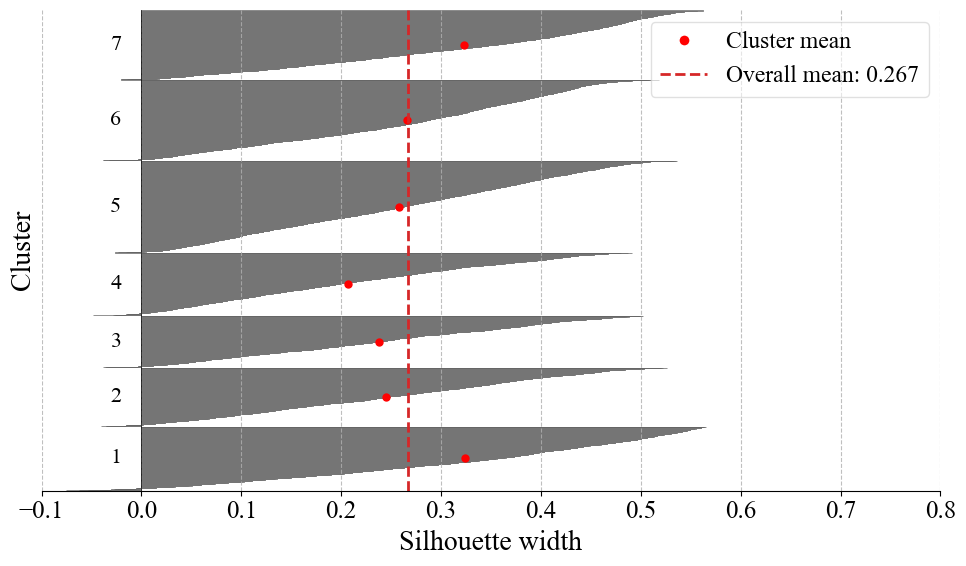

In [32]:
results_sil_pc = get_distances_between_daily_profiles(
    id_df=sorted_ids_clusters_pc,
    wind_df=wind_df,
)
fig, ax = plot_silhouettes_daily(
    results=results_sil_pc,
    xlim=(-0.1, 0.8),
    save_path=OUTPUT_DIR / "fig16_silhouette_fpca.png",
)
plt.show()


### FPCA cluster TOU boxplots

In [33]:
tou_cluster_means_pc = (
    tou_means
    .merge(sorted_ids_clusters_pc[["ID", "Cluster"]], left_index=True, right_on="ID")
    .groupby("Cluster")
    .mean(numeric_only=True)
    .reset_index()
)
sorted_ids_clusters_pc_tou = sorted_ids_clusters_pc.merge(
    tou_means, left_on="ID", right_index=True
)


### CF clustering (K=7)

In [35]:
id_df_clusters_cf = perform_clustering(
    data=cf_features,
    n_clusters=K,
    id_df=id_df_indexed,
    feature_cols=["Mean_Generation"],
)
id_df_clusters_cf.reset_index(inplace=True)

cf_gen_stats = get_mean_gen_per_cluster(id_df_clusters_cf, wind_df)

stability_summary_cf, _ = run_or_load_stability(
    data=cf_features,
    n_clusters=K,
    feature_cols=["Mean_Generation"],
    cache_path=OUTPUT_DIR / "stability_cf",
    run=RUN_STABILITY_STUDY,
    n_runs=STABILITY_N_RUNS,
    n_init_values=STABILITY_N_INIT_VALUES,
)
print(stability_summary_cf.to_string(index=False))

sorted_ids_clusters_cf, sorted_stats_cf = sort_clusters(
    id_df_clusters_cf, cf_gen_stats, sort_by="Mean_Generation"
)
sorted_ids_clusters_cf.to_csv(OUTPUT_DIR / "cluster_assignments_cf_k7.csv", index=False)
print(sorted_ids_clusters_cf.head(3))


 n_init  ari_mean  ari_min  ari_frac_above_0.99  inertia_mean  inertia_std  n_distinct_solutions
      1  0.854635 0.684939             0.113668      1.979741     0.002865                   183
      5  0.907468 0.708978             0.075729      1.976816     0.001486                   181
     10  0.923168 0.762171             0.027236      1.975887     0.001151                   190
     20  0.945746 0.766127             0.039749      1.975171     0.000781                   189
     50  0.961116 0.848621             0.065578      1.974664     0.000423                   191
      ID   Latitude  Longitude  Cluster  clustered_on Mean_Generation  \
0  22222 -34.823544  19.970032        7                      0.485992   
1  22223 -34.822390  20.007294        7                      0.485567   
2  22851 -34.794080  19.931427        7                      0.481875   

   cluster_mean_Generation  
0                 0.473201  
1                 0.473201  
2                 0.473201  


### Daily profiles by cluster (CF feature)

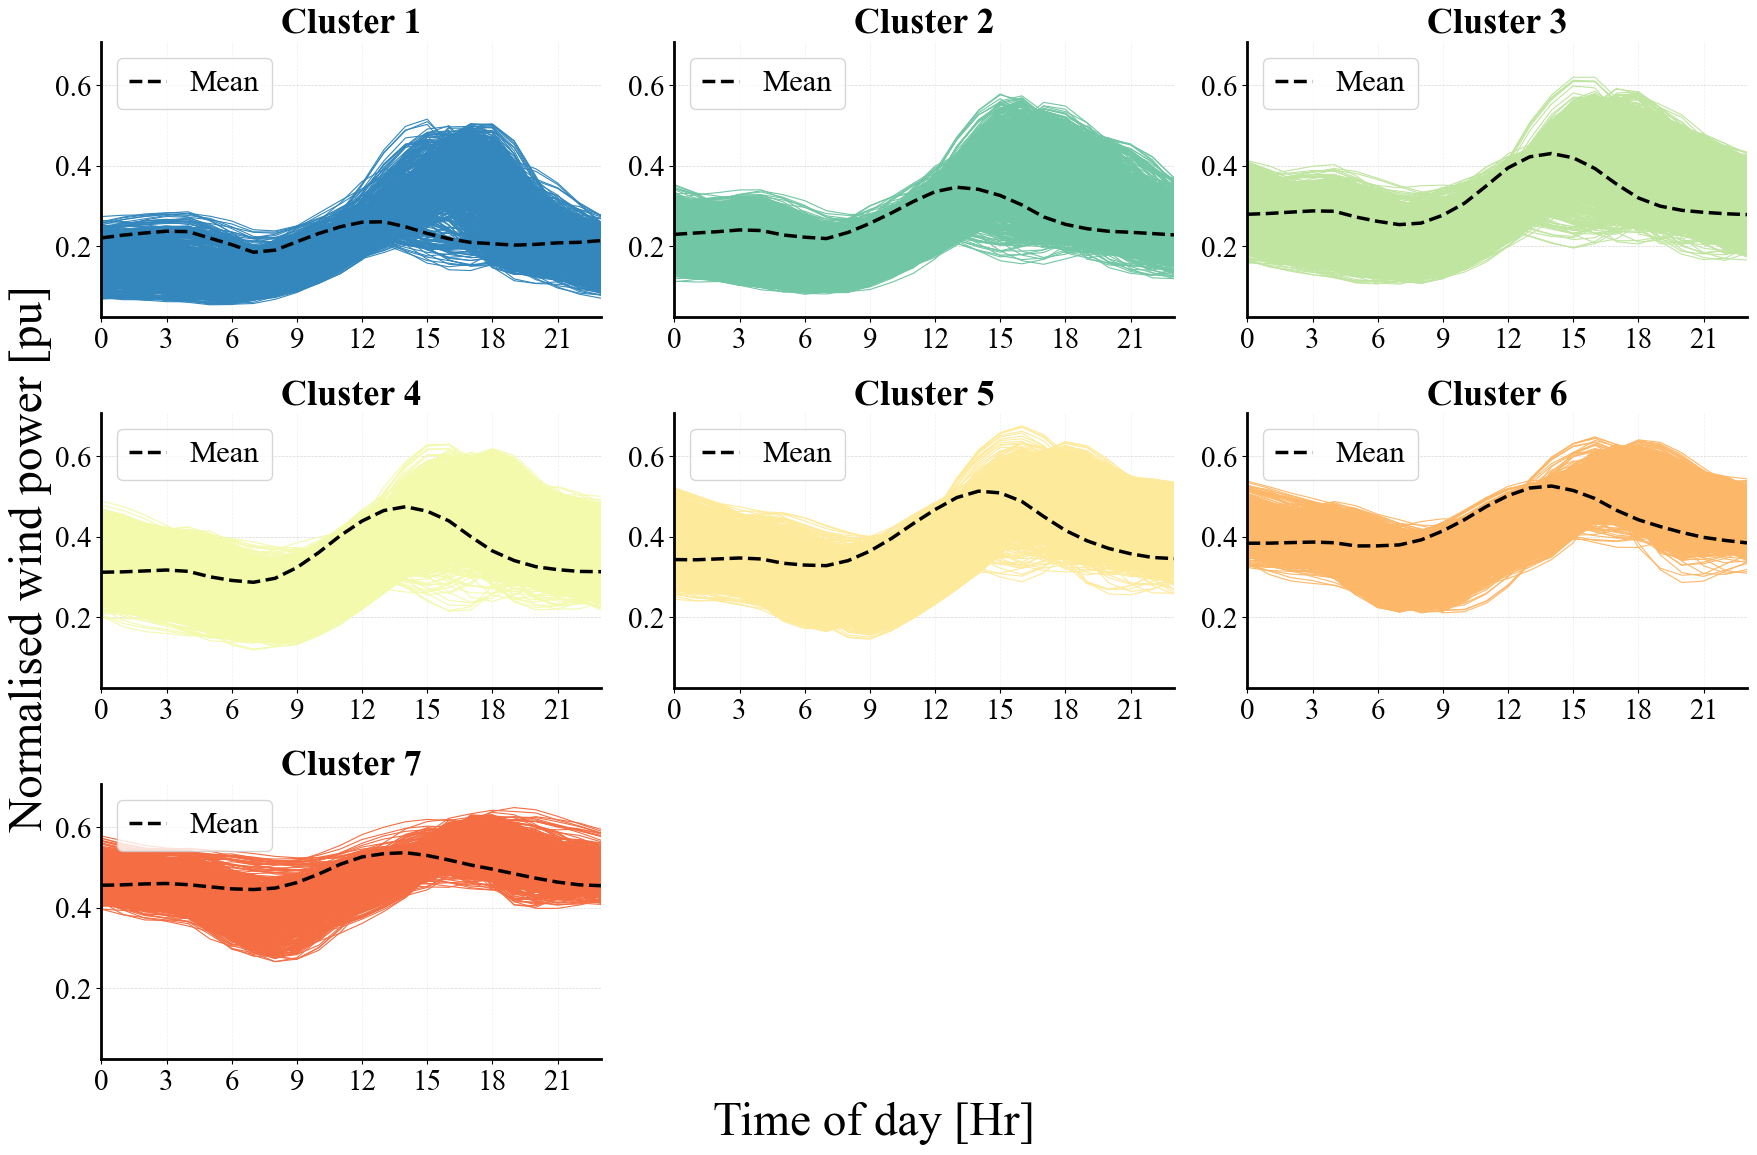

In [36]:
fig, axes = plot_daily_profiles_grid(
    wind_df=wind_df,
    id_df=sorted_ids_clusters_cf,
    save_path=OUTPUT_DIR / "fig18_profiles_cf.png",
)
plt.show()


### Silhouette (CF clustering)

Calculating daily profiles for each location...

Calculating intra-cluster distances...
Cluster 1: 911 profiles, Avg Euclidean dist: 0.3213, Avg Cosine dist: 0.0428
Cluster 2: 1396 profiles, Avg Euclidean dist: 0.3673, Avg Cosine dist: 0.0401
Cluster 3: 1754 profiles, Avg Euclidean dist: 0.3637, Avg Cosine dist: 0.0296
Cluster 4: 2111 profiles, Avg Euclidean dist: 0.3635, Avg Cosine dist: 0.0237
Cluster 5: 2221 profiles, Avg Euclidean dist: 0.3458, Avg Cosine dist: 0.0178
Cluster 6: 1667 profiles, Avg Euclidean dist: 0.2922, Avg Cosine dist: 0.0103
Cluster 7: 790 profiles, Avg Euclidean dist: 0.2550, Avg Cosine dist: 0.0053

Calculating silhouette scores...

SUMMARY
Number of locations: 10850
Number of clusters: 7

Global Silhouette Scores:
  - Euclidean: 0.1080
  - Cosine: -0.2224
Mean for cluster 1: 0.24514436963076786
Mean for cluster 2: 0.07510853622696313
Mean for cluster 3: 0.08512641331224309
Mean for cluster 4: 0.056671072288275205
Mean for cluster 5: 0.05935110705564892
Mean f

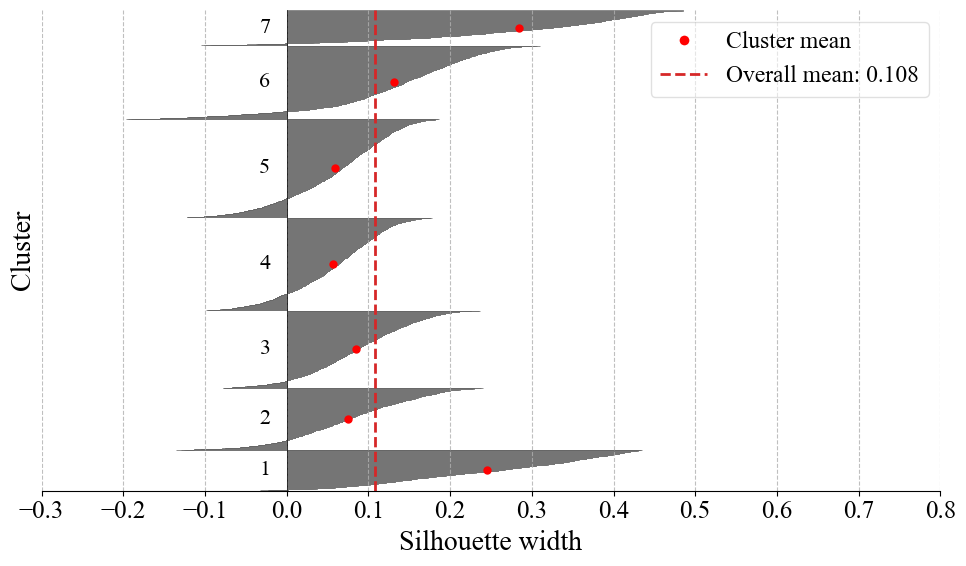

In [37]:
results_sil_cf = get_distances_between_daily_profiles(
    id_df=sorted_ids_clusters_cf,
    wind_df=wind_df,
)
fig, ax = plot_silhouettes_daily(
    results=results_sil_cf,
    xlim=(-0.3, 0.8),
    save_path=OUTPUT_DIR / "fig19_silhouette_cf.png",
)
plt.show()
